# Continuous Sensing and Batch GP Verification

    **Purpose:** check predicted along-path events, actual-position sampling, a continuous 1 Hz clock, measurement buffering, segment-end batch GP conditioning, and interrupted-edge data handling. This is an offline Python functional test, not a GRG policy comparison, ROS execution or reconstruction-accuracy study.

    The fixture uses saved Nav2 detour geometry, translated into the temporary 30 x 30 m area and traversed out/back twice. Progress, pauses and the 120 s clock are synthetic; no new robot or physics run is implied. Planned nominal timing and the actual-profile fixture intentionally differ. The same verified SRF supplies temperatures at actual inputs, without snapping to its 0.1 m visualization grid.

    Initial conditioning uses **980 synthetic historical SRF observations**, with negative times in [-600,-1] s; it does not use unregistered real ENU coordinates. Only the saved real-data RBF **hyperparameters** are reused, in physical metres/seconds/Celsius. No checkpoint conditioning data or kernel training is used. A 3920-record case is a hypothetical fourfold size proxy, not four available real datasets.

    Batch GP uses the existing exact 3D ARD RBF equations with SciPy Cholesky/triangular solves and a memory-efficient squared-distance calculation. Numerical equivalence is checked against the existing NumPy GP, and against sequential and differently partitioned conditioning.

In [1]:
from pathlib import Path
import csv,json
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display,Markdown
ROOT=Path.cwd()
RUN=ROOT/"result"/json.loads((ROOT/"result/latest.json").read_text())["run"]
def read(name):return json.loads((RUN/name).read_text())
def rows(name):
    with (RUN/name).open(newline="") as f:return list(csv.DictReader(f))
summary=read("summary.json");protocol=read("protocol.json")
checks=read("checks.json");updates=read("gp_updates.json");scales=read("scale_benchmarks.json")
measurements=rows("measurements.csv");trajectory=rows("trajectory.csv");buffer_trace=rows("buffer_trace.csv")
def col(records,key):return np.array([float(r[key]) for r in records])
print("Functional checks:",sum(r["passed"] for r in checks),"/",len(checks),"| Failed:",summary["failed_checks"])
print("Measurements:",summary["measurements"],"| Batch sizes:",summary["batch_sizes"],
      "| GP conditioning count:",summary["initial_gp_count"],"->",summary["final_gp_count"])
print("Main missed ticks:",summary["missed_main_ticks"],"| Maximum synthetic speed:",
      round(summary["maximum_fixture_speed_m_s"],4),"m/s")
print("Measured four-update wall time:",round(summary["total_batch_wall_s"]*1000,3),"ms")
print("These wall timings are separate from the synthetic 120 s trajectory clock.")
assert summary["passed"] and not summary["ros_executed"] and not summary["grg_executed"]
assert not summary["policy_comparison_performed"] and not summary["complete_120s_mission_budget_validated"]
lines=["| Segment end (s) | New observations | GP count after update | Update wall time (ms) |",
       "| ---: | ---: | ---: | ---: |"]
for u in updates:
    lines.append(f'| {u["time_s"]} | {u["batch_count"]} | {u["after_count"]} | {u["wall_update_s"]*1000:.3f} |')
display(Markdown(chr(10).join(lines)))

Functional checks: 48 / 48 | Failed: []
Measurements: 120 | Batch sizes: [23, 28, 32, 37] | GP conditioning count: 980 -> 1100
Main missed ticks: [] | Maximum synthetic speed: 0.4396 m/s
Measured four-update wall time: 52.162 ms
These wall timings are separate from the synthetic 120 s trajectory clock.


| Segment end (s) | New observations | GP count after update | Update wall time (ms) |
| ---: | ---: | ---: | ---: |
| 23.4 | 23 | 1003 | 14.874 |
| 51.7 | 28 | 1031 | 12.453 |
| 83.2 | 32 | 1063 | 11.999 |
| 120.0 | 37 | 1100 | 12.836 |

## Moving samples and predicted-input separation

    The robot-path fixture crosses noninteger-time Checkpoint boundaries. Sampling remains at the global times 1,2,...,120 s, including during the planned pause. Actual x/y/t, measurement identity, noise-free source value and noisy observed temperature are logged separately. The obstacle is shown only as context for the original saved detour; this test does not validate new controller or footprint behavior.

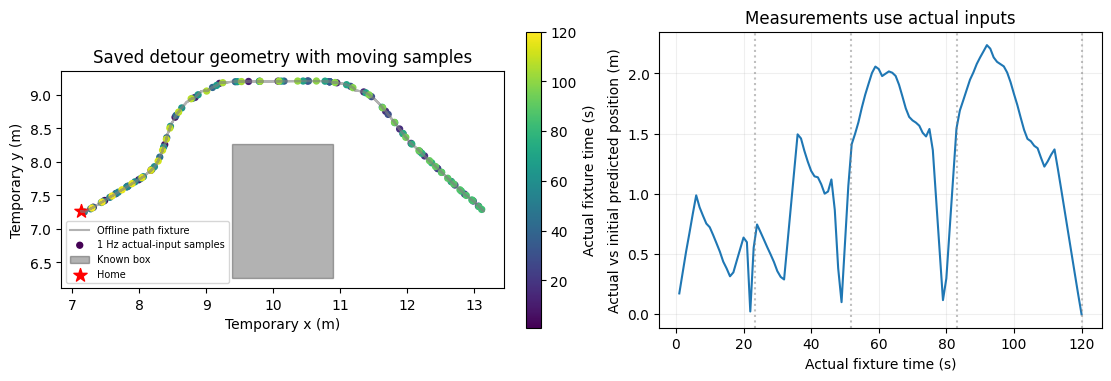

Actual sample spacing (s): [1.]
Updated-route predicted events retain absolute 1 s phase; no artificial checkpoint dwell is introduced.


In [2]:
from matplotlib.patches import Rectangle
fig,axes=plt.subplots(1,2,figsize=(11,3.7),layout="constrained")
axes[0].plot(col(trajectory,"x_m"),col(trajectory,"y_m"),color="gray",alpha=.6,label="Offline path fixture")
points=axes[0].scatter(col(measurements,"x_m"),col(measurements,"y_m"),
                       c=col(measurements,"t_s"),s=18,cmap="viridis",label="1 Hz actual-input samples")
dx,dy=protocol["fixture_translation_m"];xmin,xmax,ymin,ymax=protocol["obstacle_original_bounds_m"]
axes[0].add_patch(Rectangle((xmin+dx,ymin+dy),xmax-xmin,ymax-ymin,color="black",alpha=.3,label="Known box"))
axes[0].scatter(float(trajectory[0]["x_m"]),float(trajectory[0]["y_m"]),marker="*",s=100,c="red",label="Home")
axes[0].set(xlabel="Temporary x (m)",ylabel="Temporary y (m)",title="Saved detour geometry with moving samples",aspect="equal")
axes[0].legend(fontsize=7);fig.colorbar(points,ax=axes[0],label="Actual fixture time (s)")
axes[1].plot(col(measurements,"t_s"),col(measurements,"pose_difference_m"))
for boundary in protocol["actual_segment_end_s"]:axes[1].axvline(boundary,ls=":",color="gray",alpha=.5)
axes[1].set(xlabel="Actual fixture time (s)",ylabel="Actual vs initial predicted position (m)",
            title="Measurements use actual inputs")
axes[1].grid(alpha=.2)
fig.savefig(RUN/"figures/path_and_timing.png",dpi=180)
plt.show()
print("Actual sample spacing (s):",np.unique(np.round(np.diff(col(measurements,"t_s")),9)))
print("Updated-route predicted events retain absolute 1 s phase; no artificial checkpoint dwell is introduced.")

## Buffering, posterior updates and interruption handling

    Each successful batch commits all valid buffered records exactly once. Invalid/duplicate identities are rejected. An injected factorization failure leaves the GP and pending buffer unchanged for retry. Stationary repeated positions retain distinct timestamps and identities.

    The separate interrupted-path case stops at 42.65 s: 23 observations were already committed, and 19 valid observations from the incomplete segment are flushed. It does not invent measurements after interruption. Delayed callback checks use actual callback timestamps and explicitly log missed ticks instead of backfilling past poses.

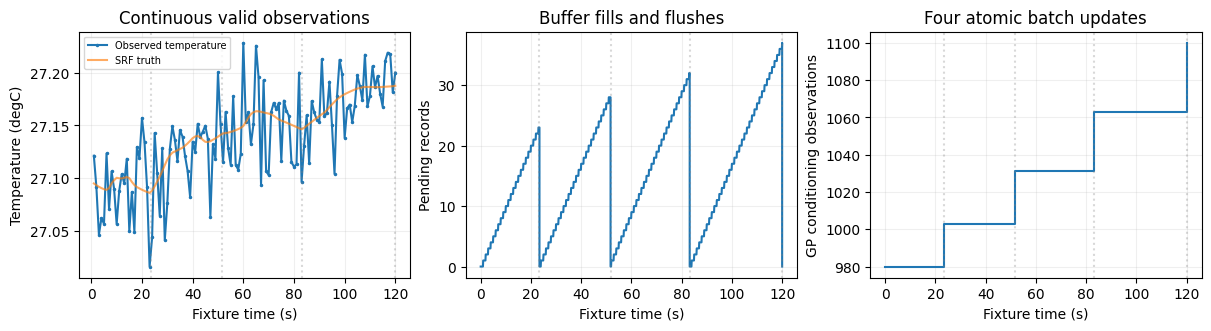

Interruption: {'failure_time_s': 42.65, 'completed_batch_count': 23, 'partial_batch_count': 19, 'total_retained': 42, 'new_gp_count': 1022, 'rule': 'Flush valid interrupted-edge samples; no backfill after failure.'}
Delayed callbacks: [('1.0', '1.08'), ('2.0', '2.04'), ('5.0', '5.03'), ('6.0', '6.1')]
Largest numerical equality-check error: 7.105427357601002e-15


In [3]:
fig,axes=plt.subplots(1,3,figsize=(12,3.2),layout="constrained")
axes[0].plot(col(measurements,"t_s"),col(measurements,"temperature_c"),".-",ms=3,label="Observed temperature")
axes[0].plot(col(measurements,"t_s"),col(measurements,"truth_c"),alpha=.65,label="SRF truth")
axes[0].set(xlabel="Fixture time (s)",ylabel="Temperature (degC)",title="Continuous valid observations")
axes[0].legend(fontsize=7)
axes[1].plot(col(buffer_trace,"t_s"),col(buffer_trace,"pending"))
axes[1].set(xlabel="Fixture time (s)",ylabel="Pending records",title="Buffer fills and flushes")
axes[2].step([0]+[u["time_s"] for u in updates],
             [summary["initial_gp_count"]]+[u["after_count"] for u in updates],where="post")
axes[2].set(xlabel="Fixture time (s)",ylabel="GP conditioning observations",title="Four atomic batch updates")
for ax in axes:
    for t in protocol["actual_segment_end_s"]:ax.axvline(t,color="gray",ls=":",alpha=.3)
    ax.grid(alpha=.2)
fig.savefig(RUN/"figures/buffer_and_updates.png",dpi=180)
plt.show()
print("Interruption:",read("failure_case.json"))
print("Delayed callbacks:",[(r["scheduled_t_s"],r["t_s"]) for r in rows("delayed_callback_measurements.csv")])
errors=[(c["name"],c["maximum_absolute_error"]) for c in checks if "maximum_absolute_error" in c]
print("Largest numerical equality-check error:",max(v for _,v in errors))

## Batch GP workload measurements

    Model parameters, thread limits and the new 120-observation batch are fixed. Both history datasets are synthetic. The 3920 case is a size proxy; it does not assert the existence or quality of four real collections. Exact batch refresh currently refactorizes the enlarged covariance matrix.

    RSS includes process/runtime allocations and retained fixture models; it is sampled every 5 ms and may miss very short peaks. Timings are one execution per scale, with no end-to-end ROS scheduling, scoring or GRG search included.

| Synthetic history | New batch | Final count | Initial factorization (s) | Batch update (s) | Sampled update peak RSS (MiB) |
| ---: | ---: | ---: | ---: | ---: | ---: |
| 980 | 120 | 1100 | 0.0073 | 0.0085 | 182.05 |
| 3920 | 120 | 4040 | 0.3339 | 0.2731 | 558.79 |

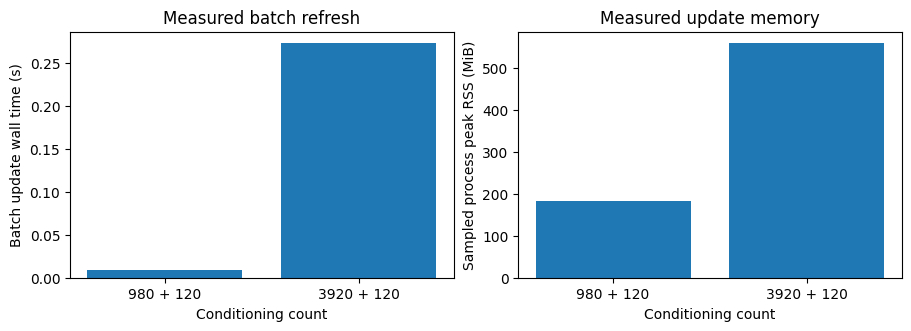

In [4]:
lines=["| Synthetic history | New batch | Final count | Initial factorization (s) | Batch update (s) | Sampled update peak RSS (MiB) |",
       "| ---: | ---: | ---: | ---: | ---: | ---: |"]
for r in scales:
    lines.append(f'| {r["history_count"]} | {r["batch_count"]} | {r["final_count"]} | {r["initial_factorization_s"]:.4f} | {r["batch_update_s"]:.4f} | {r["sampled_peak_rss_mib"]:.2f} |')
display(Markdown(chr(10).join(lines)))
fig,axes=plt.subplots(1,2,figsize=(9,3.2),layout="constrained")
labels=[str(r["history_count"])+" + 120" for r in scales]
axes[0].bar(labels,[r["batch_update_s"] for r in scales])
axes[0].set(xlabel="Conditioning count",ylabel="Batch update wall time (s)",title="Measured batch refresh")
axes[1].bar(labels,[r["sampled_peak_rss_mib"] for r in scales])
axes[1].set(xlabel="Conditioning count",ylabel="Sampled process peak RSS (MiB)",title="Measured update memory")
fig.savefig(RUN/"figures/gp_workload.png",dpi=180)
plt.show()

## Conclusion and limits

    **Functional pipeline passed:** global-phase moving sampling, predicted-event construction, actual-input temperature lookup, valid/unique buffering, four batch GP updates, posterior equivalence, missed-tick handling, and preservation of valid interrupted-edge data.

    This establishes readiness for the scoring-policy component checks. It does **not** validate GRG runtime, Adaptive WIVR, a full 120 s ROS mission, real robot sampling/synchronization or reconstruction accuracy. Real-data RBF parameters are held fixed solely for conditioning and workload tests; no kernel fitting or policy ranking was performed.

    Saved inputs and outputs: protocol.json, provenance.json, manifest.json, predicted_initial_events.csv, measurements.csv, gp_updates.csv, buffer_trace.csv, failure_case.json, scale_benchmarks.json and GP state snapshots. Shared SRF, GP source and trained-parameter files remain unchanged.